# Anemia project: end-to-end run

A hybrid agent (cited clinical rules + calibrated machine learning, with referral and abstention) that classifies one complete blood count into one of nine labels. **Research prototype, not a diagnostic tool.** See `README.md` for the project description.

**Requirements:** Python 3.12 (tested with 3.12.6), the packages in `requirements.txt`, and the dataset at `data/diagnosed_cbc_data_v4.csv` (Kaggle, *Anemia Types Classification* by E. Aboelnaga: https://www.kaggle.com/datasets/ehababoelnaga/anemia-types-classification). The setup cell stops if the file is missing or not byte-identical.

**Run:** `python -m venv .venv`, activate it, `pip install -r requirements.txt`, `jupyter lab`, open this notebook and run all cells.

**Modes:** `RUN_FULL = True` recomputes Phases 1-5 from the data in a temporary copy of the repository and checks every regenerated file against `results/` (about 15 minutes on a 16-thread desktop PC (the recompute itself took 864 s), longer on a laptop). `RUN_FULL = False` only loads and checks the committed files in `results/` (a few seconds (2 s on the same PC)). The default is `True`. The held-out test rows are never read. Phase 6 only displays the committed final-test files.

## Setup

In [1]:
RUN_FULL = True
import os
if os.environ.get("ANEMIA_RUN_FULL") in ("0", "1"):
    RUN_FULL = os.environ["ANEMIA_RUN_FULL"] == "1"
print("RUN_FULL =", RUN_FULL)

RUN_FULL = True


Python version and installed packages against `requirements.txt`.

In [2]:
import sys
import time
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
from IPython.display import display

import reproduce as R

pd.set_option("display.max_rows", 60)
pd.set_option("display.max_colwidth", 80)
T0 = time.perf_counter()
print(R.check_python())
display(R.check_packages())

Python 3.12.6 (tested version)


,package,required,installed,status
0,numpy,2.1.3,2.1.3,ok
1,pandas,3.0.5,3.0.5,ok
2,scikit-learn,1.9.0,1.9.0,ok
3,scipy,1.18.0,1.18.0,ok
4,matplotlib,3.11.1,3.11.1,ok
5,pytest,9.2.0,9.2.0,ok
6,markdown,3.11.3,3.11.3,ok
7,imbalanced-learn,0.14.2,0.14.2,ok
8,joblib,1.5.3,1.5.3,ok
9,shap,0.54.1,0.54.1,ok


Dataset check with `src/check_dataset.py`.

In [3]:
print(R.check_dataset())

file: diagnosed_cbc_data_v4.csv, bytes: 125590 (expected 125590)
sha256: f7dee8d4fe500aec6e8e4bfbeb6df6b83bc86bef03d540721e0aeaad2759fcdb
expected: f7dee8d4fe500aec6e8e4bfbeb6df6b83bc86bef03d540721e0aeaad2759fcdb
OK: dataset matches


Temporary copy of the repository for the full recompute (only when `RUN_FULL` is True).

In [4]:
WS = R.Workspace() if RUN_FULL else None
print("full recompute in a temporary copy" if RUN_FULL else "checking the committed results only")

full recompute in a temporary copy


## Phase 1: data audit and cleaning

Phase 1 recomputed in 2 s
10 files: identical 9, committed only (not written by the phase scripts) 1
development rows 985, rejected 22, kept 963, label cascade reproduces 98.3% of development labels


,clean development rows
Diagnosis,
Healthy,256
Normocytic hypochromic anemia,209
Normocytic normochromic anemia,202
Iron deficiency anemia,144
Thrombocytopenia,54
Other microcytic anemia,41
Leukemia,35
Macrocytic anemia,13
Leukemia with thrombocytopenia,9


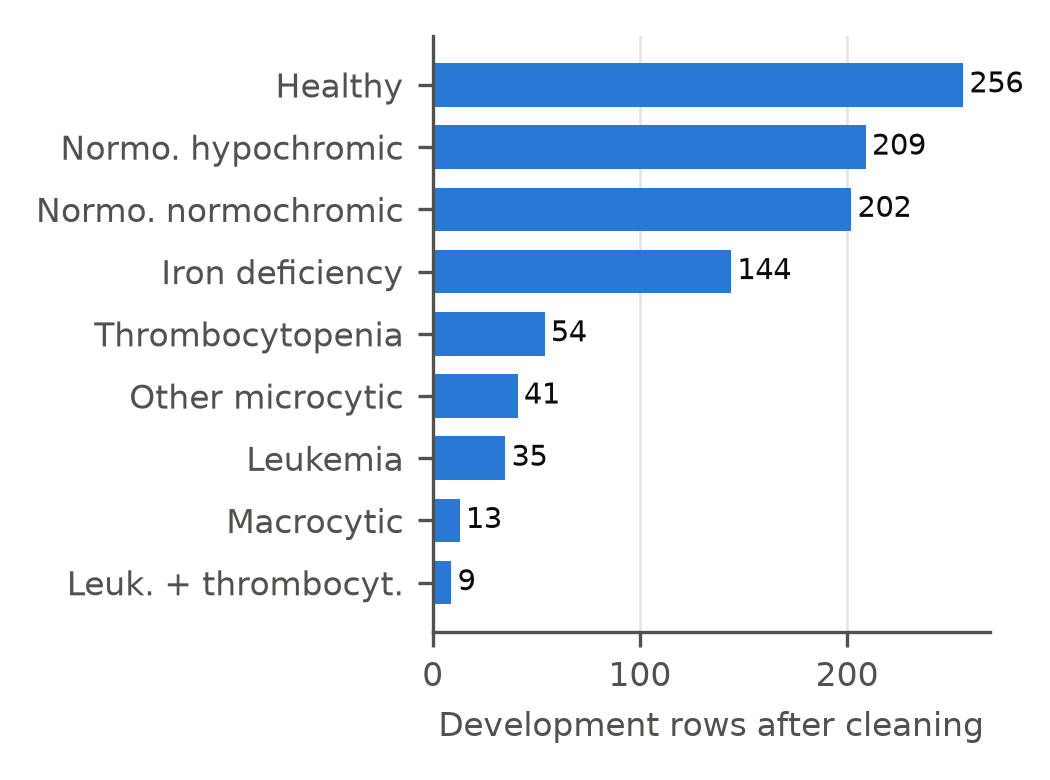

In [5]:
if RUN_FULL:
    R.assert_reproduced(WS.run_phase(1))
display(R.check_phase1())
display(R.figure("phase1/figures/fig_class_counts.png", 520))

## Phase 2: rule engine and rules-only baseline

In [6]:
if RUN_FULL:
    R.assert_reproduced(WS.run_phase(2))
display(R.check_phase2())
R.show_text("phase2/cascade_frozen.json")

Phase 2 recomputed in 1 s
4 files: identical 3, committed only (not written by the phase scripts) 1


,thresholds,rule-set coverage,mean set size
0,primary,784/963 (81.4%),1.47
1,hgb12,634/963 (65.8%),1.42
2,mchc32,929/963 (96.5%),1.47
3,hgb12_mchc32,741/963 (76.9%),1.42


{
  "hgb": 13.0,
  "plt": 150.0,
  "wbc": 10.0,
  "mcv_micro": 80.0,
  "mcv_macro": 100.0,
  "mchc_normo": 32.0,
  "mchc_ida_oma": 31.9,
  "note": "Probable labeling rule read off DEVELOPMENT data (Phase 1 audit + one fitted MCHC split). Not a clinical rule. Frozen 14 Nov 2026. Score once on the test set in Phase 6.",
  "fitted_on": "963 clean development rows",
  "fit_rule": "MCHC split maximising balanced accuracy between iron deficiency and other microcytic on development rows labelled with either, grid 28.0-34.0 step 0.1, lowest value at the maximum"
}


## Phase 3: ML evaluation

Phase 3 recomputed in 559 s


51 files: identical 38, identical after line endings and timing are ignored 6, committed only (not written by the phase scripts) 3, log or timing, not compared 2, identical except timing column 2
H2 model (pre-declared rule): random forest + SMOTE, F-core macro-F1 0.9746


macro_f1       
                   mean    std
model  imb                    
dummy  none       0.047  0.000
forest smote      0.975  0.022
       weights    0.968  0.024
hgb    smote      0.945  0.045
       weights    0.940  0.035
logreg smote      0.863  0.050
       weights    0.854  0.043
tree   smote      0.962  0.026
       weights    0.970  0.029

| Feature set | Model (arm) | Macro-F1 all rows | Balanced acc. all rows | MCC all rows | Macro-F1 mean-filled rows | Macro-F1 other rows |
|---|---|---|---|---|---|---|
| F-core | Majority dummy | 0.047 ± 0.000 | 0.111 ± 0.000 | 0.000 ± 0.000 | 0.066 ± 0.004 | 0.023 ± 0.006 |
| F-core | Logistic regression (SMOTE) | 0.863 ± 0.050 | 0.886 ± 0.049 | 0.896 ± 0.026 | 0.852 ± 0.061 | 0.812 ± 0.093 |
| F-core | Decision tree (class weights) | 0.970 ± 0.029 | 0.974 ± 0.028 | 0.990 ± 0.008 | 0.988 ± 0.020 | 0.944 ± 0.061 |
| F-core | Random forest (SMOTE) | 0.975 ± 0.022 | 0.977 ± 0.023 | 0.988 ± 0.009 | 0.979 ± 0.039 | 0.946 ± 0.054 |
| F-core | Gradient boosting (SMOTE) | 0.945 ± 0.045 | 0.945 ± 0.046 | 0.977 ± 0.012 | 0.967 ± 0.037 | 0.894 ± 0.069 |
| F-all | Majority dummy | 0.047 ± 0.000 | 0.111 ± 0.000 | 0.000 ± 0.000 | 0.066 ± 0.004 | 0.023 ± 0.006 |
| F-all | Logistic regression (SMOTE) | 0.836 ± 0.058 | 0.854 ± 0.060 | 0.871 ± 0.034 | 0.814 ± 0.067 | 0.757 ± 0.085 |
| F-all | Decision tree (class weights) | 0.972 ± 0.028 | 0.974 ± 0.033 | 0.990 ± 0.010 | 0.983 ± 0.040 | 0.948 ± 0.064 |
| F-all | Random forest (SMOTE) | 0.954 ± 0.039 | 0.954 ± 0.045 | 0.979 ± 0.012 | 0.949 ± 0.057 | 0.917 ± 0.075 |
| F-all | Gradient boosting (SMOTE) | 0.941 ± 0.038 | 0.944 ± 0.043 | 0.976 ± 0.013 | 0.945 ± 0.054 | 0.904 ± 0.075 |


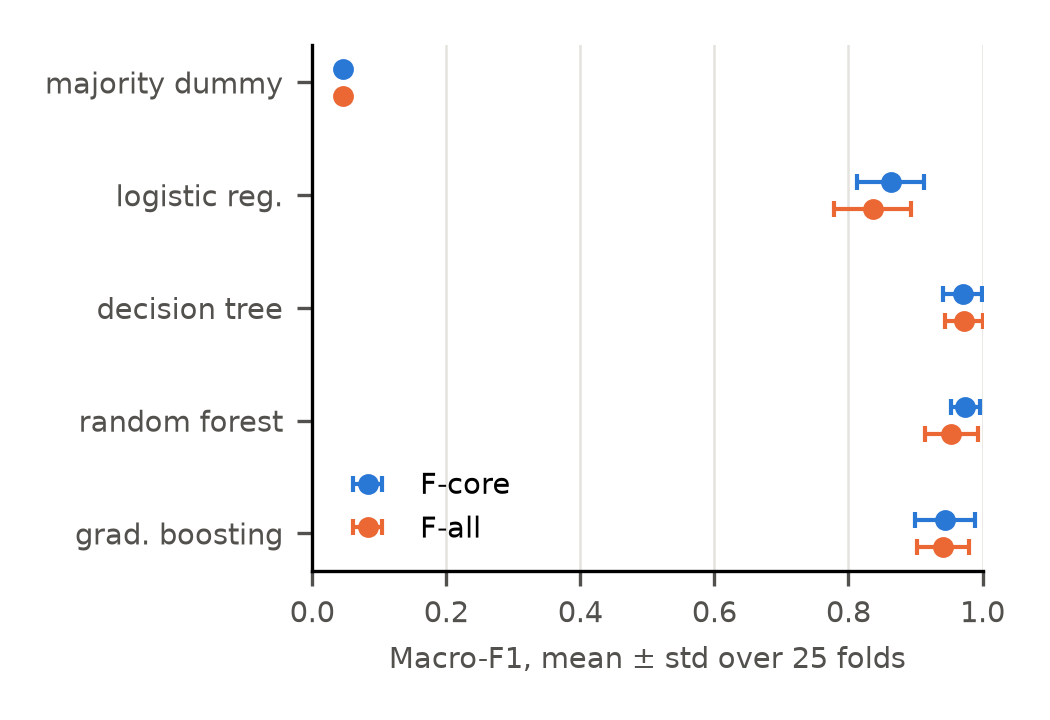

In [7]:
if RUN_FULL:
    R.assert_reproduced(WS.run_phase(3))
display(R.check_phase3())
display(R.show_md("phase3/amended/main_results_table.md"))
display(R.figure("phase3/amended/figures/fig_macro_f1_by_model.png", 420))

## Phase 4: hybrid and abstention

Phase 4 recomputed in 138 s
21 files: identical 16, identical after line endings and timing are ignored 2, identical except timing column 1, log or timing, not compared 1, committed only (not written by the phase scripts) 1


{'H1 supported (main thresholds)': 0,
 'H2 passes': False,
 'REFER trigger': 'ml',
 'tau (main)': 0.92}

H1: hybrid without abstention vs the same model alone (macro-F1, 9 classes, mean ± std over 25 folds).

| Thresholds | Model | Macro-F1 alone | Macro-F1 hybrid | Difference [90% CI] | H1 |
|---|---|---|---|---|---|
| HGB 13, MCHC 30 (main) | logistic regression | 0.863 ± 0.050 | 0.769 ± 0.050 | -0.094 [-0.147, -0.042] | fail |
| HGB 13, MCHC 30 (main) | decision tree | 0.970 ± 0.029 | 0.780 ± 0.041 | -0.191 [-0.232, -0.149] | fail |
| HGB 13, MCHC 30 (main) | random forest | 0.975 ± 0.022 | 0.787 ± 0.045 | -0.188 [-0.230, -0.146] | fail |
| HGB 13, MCHC 30 (main) | gradient boosting | 0.945 ± 0.045 | 0.760 ± 0.040 | -0.185 [-0.225, -0.144] | fail |
| HGB 12, MCHC 30 | logistic regression | 0.863 ± 0.050 | 0.657 ± 0.044 | -0.206 [-0.250, -0.162] | fail |
| HGB 12, MCHC 30 | decision tree | 0.970 ± 0.029 | 0.663 ± 0.037 | -0.307 [-0.346, -0.268] | fail |
| HGB 12, MCHC 30 | random forest | 0.975 ± 0.022 | 0.669 ± 0.035 | -0.305 [-0.343, -0.268] | fail |
| HGB 12, MCHC 30 | gradient boosting | 0.945 ± 0.045 | 0.645 ± 0.034 | -0.299 [-0.336, -0.263] | fail |
| HGB 13, MCHC 32 | logistic regression | 0.863 ± 0.050 | 0.860 ± 0.047 | -0.003 [-0.053, +0.047] | fail |
| HGB 13, MCHC 32 | decision tree | 0.970 ± 0.029 | 0.876 ± 0.039 | -0.094 [-0.136, -0.052] | fail |
| HGB 13, MCHC 32 | random forest | 0.975 ± 0.022 | 0.885 ± 0.043 | -0.090 [-0.132, -0.047] | fail |
| HGB 13, MCHC 32 | gradient boosting | 0.945 ± 0.045 | 0.864 ± 0.040 | -0.081 [-0.121, -0.040] | fail |
| HGB 12, MCHC 32 (suppl.) | logistic regression | 0.863 ± 0.050 | 0.728 ± 0.041 | -0.135 [-0.178, -0.092] | fail |
| HGB 12, MCHC 32 (suppl.) | decision tree | 0.970 ± 0.029 | 0.737 ± 0.037 | -0.234 [-0.273, -0.194] | fail |
| HGB 12, MCHC 32 (suppl.) | random forest | 0.975 ± 0.022 | 0.743 ± 0.035 | -0.231 [-0.270, -0.192] | fail |
| HGB 12, MCHC 32 (suppl.) | gradient boosting | 0.945 ± 0.045 | 0.726 ± 0.035 | -0.219 [-0.256, -0.182] | fail |

H2: selective macro-F1 (6 non-referral classes) at matched coverage, random forest + SMOTE.

| Thresholds | Floor | Coverage | Hybrid | Confidence-only | Random | Holm p (random, conf.) | H2 |
|---|---|---|---|---|---|---|---|
| HGB 13, MCHC 30 (main) | 70% | 71.4% | 0.997 | 1.000 | 0.850 | 0.0010, 0.9985 | fail |
| HGB 13, MCHC 30 (main) | 60% | 70.9% | 0.997 | 1.000 | 0.850 | 0.0010, 0.9985 | fail |
| HGB 13, MCHC 30 (main) | 80% | 72.9% | 0.993 | 1.000 | 0.850 | 0.0010, 0.9985 | fail |
| HGB 12, MCHC 30 | 70% | 57.3% | 0.992 | 1.000 | 0.716 | 0.0010, 0.9950 | fail |
| HGB 12, MCHC 30 | 60% | 57.3% | 0.992 | 1.000 | 0.716 | 0.0010, 0.9950 | fail |
| HGB 12, MCHC 30 | 80% | 57.3% | 0.992 | 1.000 | 0.716 | 0.0010, 0.9950 | fail |
| HGB 13, MCHC 32 | 70% | 85.7% | 0.997 | 0.996 | 0.985 | 0.0010, 0.3648 | fail |
| HGB 13, MCHC 32 | 60% | 85.7% | 0.997 | 0.996 | 0.985 | 0.0010, 0.3648 | fail |
| HGB 13, MCHC 32 | 80% | 85.7% | 0.997 | 0.996 | 0.985 | 0.0010, 0.3648 | fail |
| HGB 12, MCHC 32 (suppl.) | 70% | 68.4% | 0.994 | 1.000 | 0.822 | 0.0010, 0.9950 | fail |
| HGB 12, MCHC 32 (suppl.) | 60% | 66.6% | 0.997 | 1.000 | 0.822 | 0.0010, 0.9960 | fail |
| HGB 12, MCHC 32 (suppl.) | 80% | 68.4% | 0.994 | 1.000 | 0.822 | 0.0010, 0.9950 | fail |


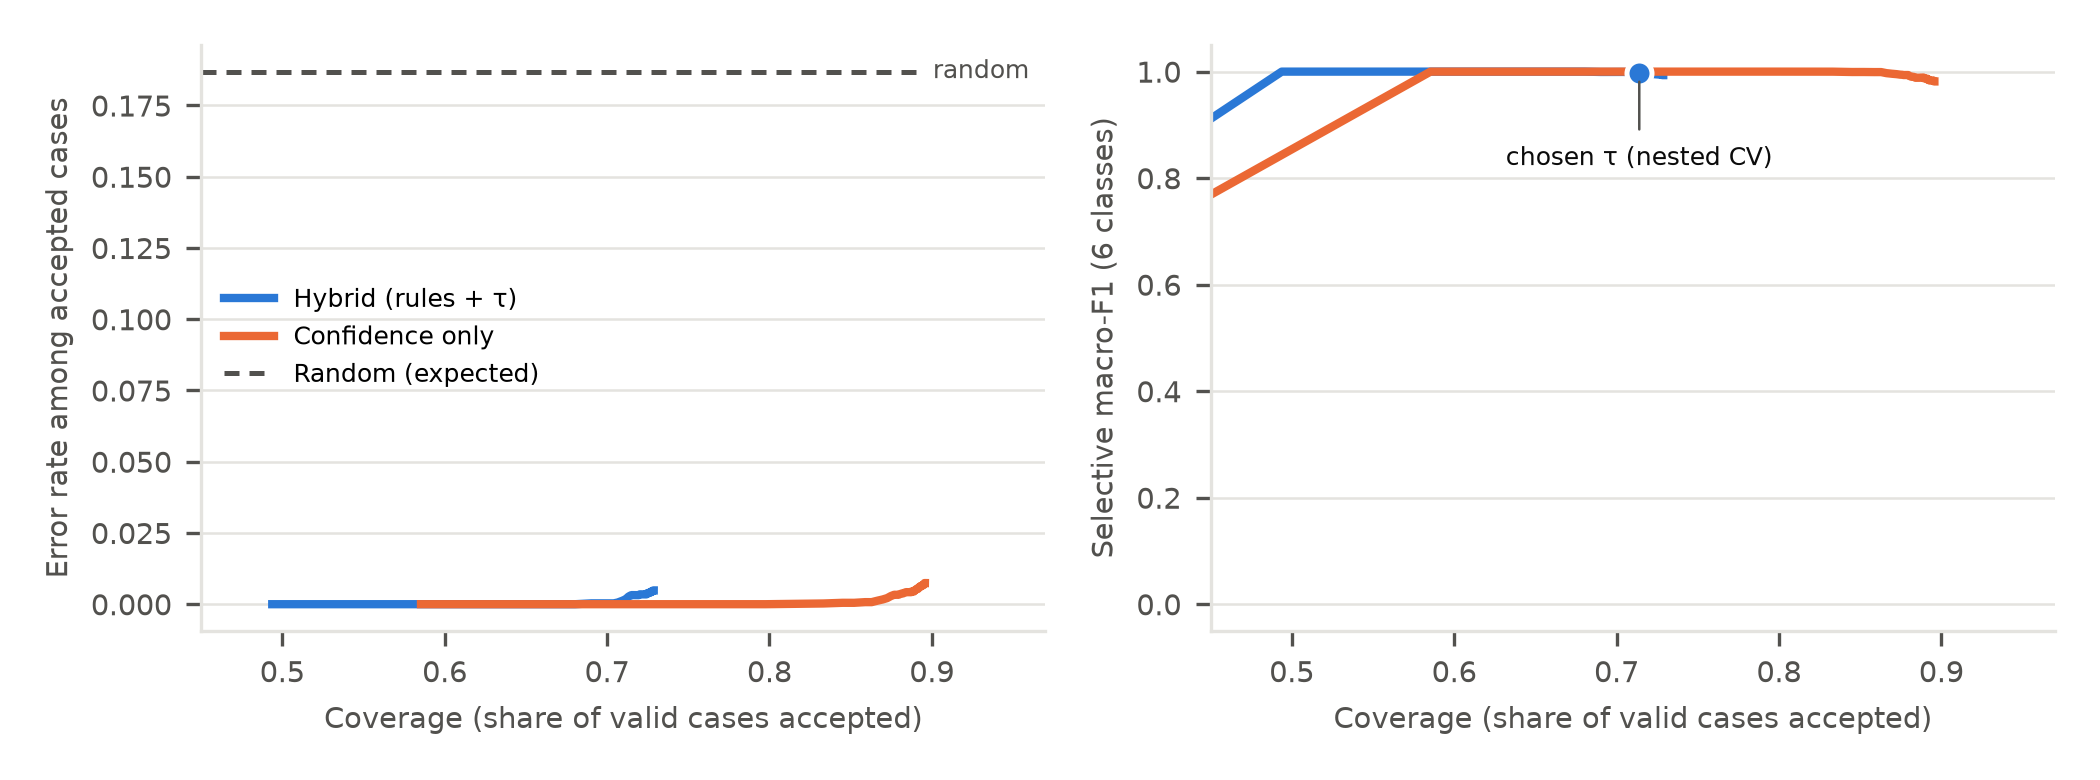

In [8]:
if RUN_FULL:
    R.assert_reproduced(WS.run_phase(4))
display(R.check_phase4())
display(R.show_md("phase4/main_results_table_part_b.md"))
display(R.figure("phase4/figures/fig_risk_coverage.png", 760))

## Phase 5: explanations, audit log, stress tests

Phase 5 recomputed in 146 s
24 files: identical 16, committed only (not written by the phase scripts) 5, log or timing, not compared 1, identical after line endings and timing are ignored 1, identical except timing column 1


,check,result
0,consistency of saved audit records (recomputed),963/963
1,bad input caught,11200/11200
2,referral stress cases referred,601/601


== 2. the agent on all development rows (main thresholds, tau and REFER trigger frozen in Phase 4) ==
  audit log: results/phase5/audit_log_dev.jsonl (963 JSON records, one per case)
  consistency check (rule trace and SHAP refer to the same case and class as the decision, summary repeats
  the stored label and probability, caveat and disclaimer present): 963/963 pass
  decisions (IN-SAMPLE, not an accuracy result): ACCEPT 702, ABSTAIN 163, REFER 98 | reasons: ACCEPT 702, DISAGREE 163, REFER 98
  latency per case in ms (desktop PC, one case at a time):
    validation   median    0.038   95th percentile    0.051   max    0.088
    rules        median    0.053   95th percentile    0.111   max   66.198
    ml           median    8.090   95th percentile    8.983   max   13.721
    arbitration  median    0.051   95th percentile    0.067   max    0.897
    explanation  median    2.111   95th percentile    2.517   max    5.080
    audit        median    0.054   95th percentile    0.065   max 

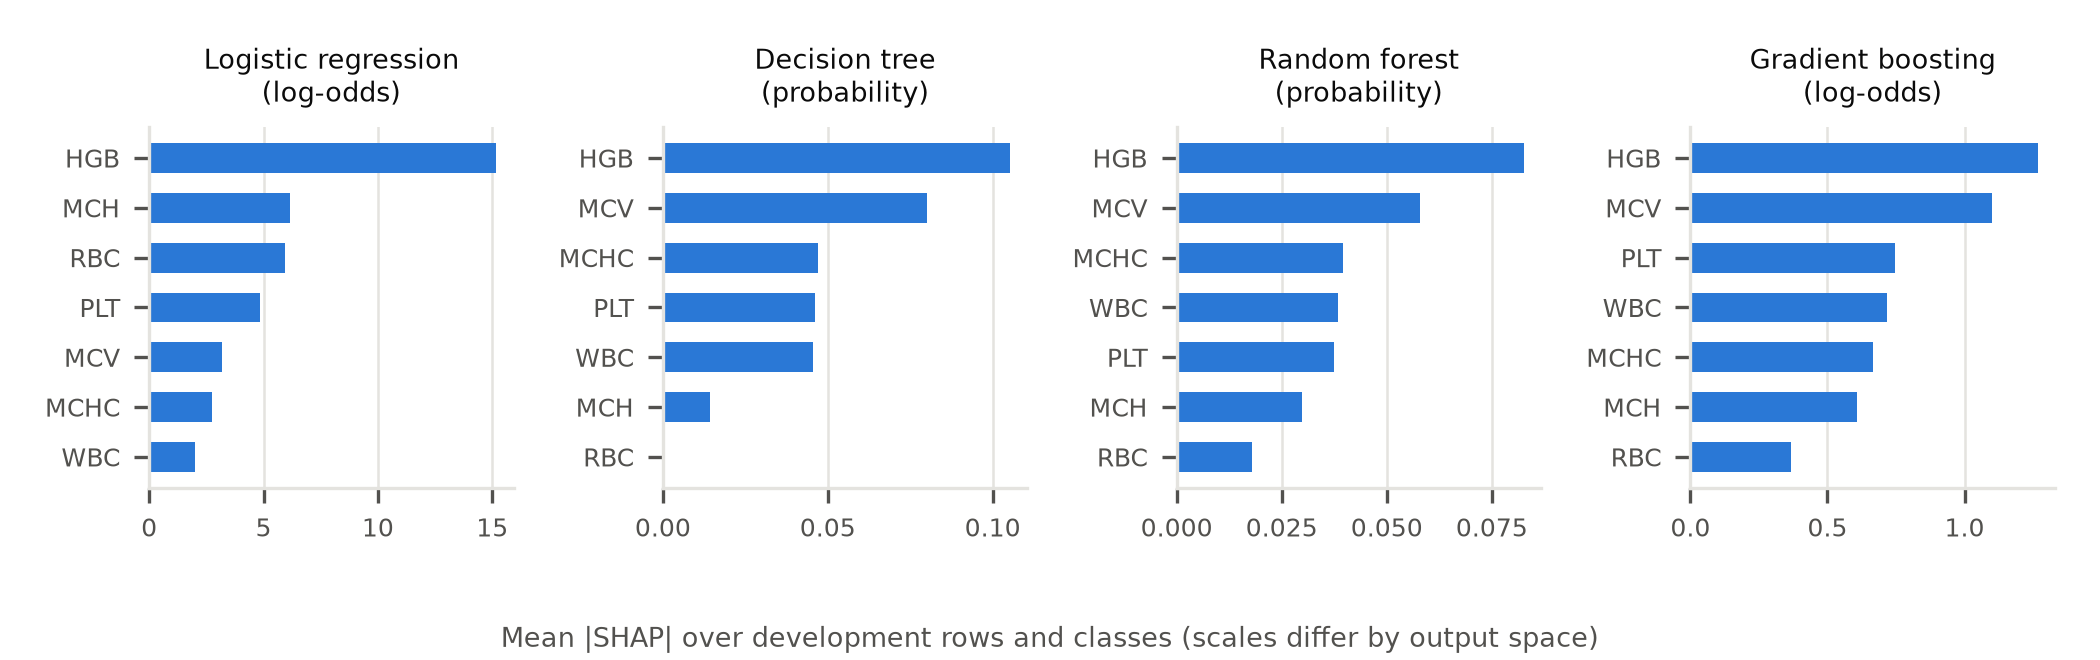

In [9]:
if RUN_FULL:
    R.assert_reproduced(WS.run_phase(5))
display(R.check_phase5())
R.show_text("phase5/phase5_report.txt", start="== 2.", stop="== 3.")
display(R.figure("phase5/figures/fig_global_shap.png", 760))

## Phase 6: final held-out results (read-only display of the committed files)

In [10]:
if R.phase6_available():
    manifest = R.check_freeze_manifest()
    print(f"frozen files checked against results/phase5/freeze_manifest.json: {len(manifest)}")
    print(manifest.status.value_counts().to_string())
    final = R.phase6_summary()
    display(final["targets"])
    display(R.show_md("phase6/main_results_table_part_d.md"))
else:
    print("final test not yet run")

frozen files checked against results/phase5/freeze_manifest.json: 22
status
matches    22


,target,name,measured_on,result,pass
0,1,Referral,test stress cases,163/163 trigger-met stress cases returned REFER,True
1,2,Validation,test rows with injected values,27104/27104 injected values caught; real invalid rows rejected: True,True
2,3,Explanations,test cases,consistency check passed on 247/247 cases,True
3,4,H1,development CV (Phase 4),0 of 4 model types pass at the main thresholds,False
4,5,H2,development CV (Phase 4),beats random but not confidence-only,False


## Systems, nine classes

| System | Thresholds | Macro-F1 | Balanced acc. | MCC | Macro-F1 mean-filled | Macro-F1 other |
|---|---|---|---|---|---|---|
| random forest | - | 0.934 | 0.907 | 0.990 | 0.973 | 0.952 |
| cascade baseline | - | 0.975 | 0.980 | 0.955 | 0.965 | 0.969 |
| hybrid no abstention | HGB 13, MCHC 30 (main) | 0.733 | 0.768 | 0.770 | 0.862 | 0.635 |
| hybrid no abstention | HGB 13, MCHC 32 | 0.821 | 0.839 | 0.915 | 0.927 | 0.823 |
| hybrid no abstention | HGB 12, MCHC 30 | 0.646 | 0.682 | 0.589 | 0.760 | 0.541 |
| hybrid no abstention | HGB 12, MCHC 32 | 0.717 | 0.736 | 0.717 | 0.819 | 0.665 |

## Expert system alone

| Thresholds | Rule-set coverage | Mean set size |
|---|---|---|
| HGB 13, MCHC 30 (main) | 78.9% | 1.46 |
| HGB 13, MCHC 32 | 93.0% | 1.46 |
| HGB 12, MCHC 30 | 65.3% | 1.43 |
| HGB 12, MCHC 32 | 76.0% | 1.43 |

## The agent with abstention (frozen settings)

| Thresholds | τ | Coverage | Selective macro-F1 | Errors / accepted | Confidence-only (same coverage, descriptive) | Referral caught | False referrals |
|---|---|---|---|---|---|---|---|
| HGB 13, MCHC 30 (main) | 0.92 | 66.5% | 1.000 | 0 / 161 | 0.833 | 26/26 | 0 |
| HGB 13, MCHC 32 | 0.96 | 78.9% | 1.000 | 0 / 191 | 1.000 | 26/26 | 0 |
| HGB 12, MCHC 30 | 0.00 | 55.8% | 1.000 | 0 / 135 | 0.833 | 26/26 | 0 |
| HGB 12, MCHC 32 | 0.00 | 66.5% | 1.000 | 0 / 161 | 0.833 | 26/26 | 0 |

## McNemar tests (continuity-corrected, Holm within each threshold version)

| Thresholds | Pair (A vs B) | A right, B wrong | A wrong, B right | p | exact p | Holm p |
|---|---|---|---|---|---|---|
| HGB 13, MCHC 30 (main) | forest vs hybrid | 50 | 1 | 0 | 0 | 0 |
| HGB 13, MCHC 30 (main) | forest vs cascade | 9 | 2 | 0.0704 | 0.0654 | 0.0704 |
| HGB 13, MCHC 30 (main) | hybrid vs cascade | 1 | 43 | 0 | 0 | 0 |
| HGB 13, MCHC 32 | forest vs hybrid | 16 | 1 | 0.000685 | 0.000275 | 0.00137 |
| HGB 13, MCHC 32 | hybrid vs cascade | 1 | 9 | 0.0269 | 0.0215 | 0.0269 |
| HGB 12, MCHC 30 | forest vs hybrid | 83 | 1 | 0 | 0 | 0 |
| HGB 12, MCHC 30 | hybrid vs cascade | 1 | 76 | 0 | 0 | 0 |
| HGB 12, MCHC 32 | forest vs hybrid | 57 | 1 | 0 | 0 | 0 |
| HGB 12, MCHC 32 | hybrid vs cascade | 1 | 50 | 0 | 0 | 0 |

## Acceptance targets

| # | Target | Measured on | Result | Verdict |
|---|---|---|---|---|
| 1 | 0 | test stress cases | 163/163 trigger-met stress cases returned REFER | pass |
| 2 | 1 | test rows with injected values | 27104/27104 injected values caught; real invalid rows rejected: True | pass |
| 3 | 2 | test cases | consistency check passed on 247/247 cases | pass |
| 4 | 3 | development CV (Phase 4) | 0 of 4 model types pass at the main thresholds | fail |
| 5 | 4 | development CV (Phase 4) | beats random but not confidence-only | fail |

## Per-class recall (valid test rows)

| Class | Test rows | Forest | Cascade | Hybrid (main) |
|---|---|---|---|---|
| Healthy | 65 | 1.00 | 1.00 | 0.92 |
| Normocytic hypochromic anemia | 53 | 1.00 | 0.85 | 0.21 |
| Normocytic normochromic anemia | 49 | 1.00 | 1.00 | 1.00 |
| Iron deficiency anemia | 37 | 1.00 | 0.97 | 1.00 |
| Thrombocytopenia | 15 | 1.00 | 1.00 | 1.00 |
| Other microcytic anemia | 9 | 1.00 | 1.00 | 1.00 |
| Leukemia | 9 | 1.00 | 1.00 | 0.78 |
| Macrocytic anemia (caveat: ≤ 5 rows) | 3 | 0.67 | 1.00 | 1.00 |
| Leukemia with thrombocytopenia (caveat: ≤ 5 rows) | 2 | 0.50 | 1.00 | 0.00 |


Clean-up and total run time.

In [11]:
if WS is not None:
    WS.cleanup()
print(f"notebook finished in {time.perf_counter() - T0:.0f} s (RUN_FULL = {RUN_FULL})")

notebook finished in 850 s (RUN_FULL = True)
